In [1]:
print("student performance etl")

student performance etl


In [2]:
# Student Performance ETL Project
# ETL = Extract, Transform, Load
# Libraries: NumPy, Pandas, Matplotlib, Seaborn
# Matplotlib and Seaborn are used for optional validation charts only.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# -------------------------
# 1. EXTRACT
# -------------------------
input_file = "https://raw.githubusercontent.com/rajendra0968jangid/Ds-Arya/main/student_performance_raw.csv"
df = pd.read_csv(input_file)

print("RAW DATA PREVIEW")
print(df.head())
print("\nRaw shape:", df.shape)
print("\nRaw data types:")
print(df.dtypes)
print("\nRaw missing values:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())


RAW DATA PREVIEW
  student_id    student_name  gender age class_section study_hours_per_day  \
0      ST001   Rahul Sharma     Male  16          10-A                  2    
1      ST002     Priya Verma  Female  15          10-A                   5   
2      ST003      Amit Kumar       M  16          10-A                   3   
3      ST004      Neha Singh  female  15          10-B                   6   
4      ST005     Arjun Mehta    Male  16          10-B                   4   

   math_score  science_score  english_score  attendance_pct assessment_date  
0        78.0             85             81              92      2025-01-12  
1        95.0             91             94              98      2025-01-12  
2        65.0             70             68              75      2025-01-13  
3        88.0             92             90              96      2025-01-13  
4        72.0             75             70              80      2025-01-14  

Raw shape: (40, 11)

Raw data types:
student_

In [4]:
# Keep a copy so we can compare before and after transformation.
raw_df = df.copy()


In [5]:
# -------------------------
# 2. TRANSFORM: normalize text
# -------------------------
text_cols = ["student_id", "student_name", "gender", "class_section"]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()

# Standardize gender values
gender_map = {
    "M": "Male", "MALE": "Male", "Male": "Male",
    "F": "Female", "FEMALE": "Female", "Female": "Female"
}
df["gender"] = df["gender"].replace(gender_map)


In [6]:
# Convert numeric columns safely. Invalid text becomes missing for review.
numeric_cols = [
    "age", "study_hours_per_day", "math_score",
    "science_score", "english_score", "attendance_pct"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")


In [7]:
# Parse dates safely; invalid date strings become NaT.
df["assessment_date"] = pd.to_datetime(
    df["assessment_date"], errors="coerce"
)

In [8]:
# -------------------------
# 3. TRANSFORM: identify duplicates
# -------------------------
print("\nDuplicate student IDs:", df["student_id"].duplicated().sum())
# The sample includes a repeated student record with a different ID.
# Use a practical composite key after trimming text and parsing the date.
duplicate_key = ["student_name", "class_section", "assessment_date"]
print("Repeated name/class/date combinations:", df.duplicated(subset=duplicate_key).sum())
df = df.drop_duplicates(subset=duplicate_key, keep="first").copy()
# Also enforce unique student IDs in case an ID itself is repeated.
df = df.drop_duplicates(subset="student_id", keep="first").copy()



Duplicate student IDs: 0
Repeated name/class/date combinations: 1


In [9]:
# -------------------------
# 4. TRANSFORM: validate values
# -------------------------
# Define valid ranges. Invalid values are set to missing rather than guessed.
df.loc[~df["age"].between(10, 25), "age"] = np.nan
df.loc[~df["study_hours_per_day"].between(0, 24), "study_hours_per_day"] = np.nan

score_cols = ["math_score", "science_score", "english_score"]
for col in score_cols:
    df.loc[~df[col].between(0, 100), col] = np.nan

df.loc[~df["attendance_pct"].between(0, 100), "attendance_pct"] = np.nan

# Standardize class labels to uppercase
df["class_section"] = df["class_section"].str.upper()


In [10]:
# -------------------------
# 5. TRANSFORM: handle missing values
# -------------------------
# For this teaching exercise, retain rows with missing measurements.
# Do not invent names/IDs; records without IDs or names are removed.
df = df.dropna(subset=["student_id", "student_name"]).copy()

# Fill missing numeric measurements with the median of that column.
# This is a simple classroom strategy; in real analysis, decide based on context.
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing gender/class/date with explicit labels or leave date missing.
df["gender"] = df["gender"].fillna("Not specified")
df["class_section"] = df["class_section"].fillna("Not specified")


In [11]:
# -------------------------
# 6. TRANSFORM: create useful columns
# -------------------------
df["average_score"] = df[score_cols].mean(axis=1).round(2)
df["total_score"] = df[score_cols].sum(axis=1)
df["performance_band"] = np.select(
    [
        df["average_score"] >= 90,
        df["average_score"] >= 75,
        df["average_score"] >= 60,
    ],
    ["Excellent", "Good", "Needs Improvement"],
    default="At Risk"
)

# Optional quality flags for review
df["date_missing_flag"] = df["assessment_date"].isna()

# Arrange columns in a clear output order
output_cols = [
    "student_id", "student_name", "gender", "age", "class_section",
    "study_hours_per_day", "math_score", "science_score", "english_score",
    "attendance_pct", "average_score", "total_score", "performance_band",
    "assessment_date", "date_missing_flag"
]
clean_df = df[output_cols].sort_values("student_id").reset_index(drop=True)

print("\nCLEANED DATA PREVIEW")
print(clean_df.head(10))
print("\nCleaned shape:", clean_df.shape)
print("\nMissing values after transformation:")
print(clean_df.isna().sum())
print("\nPerformance band counts:")
print(clean_df["performance_band"].value_counts())
print("\nGender values:")
print(clean_df["gender"].value_counts(dropna=False))



CLEANED DATA PREVIEW
  student_id  student_name  gender   age class_section  study_hours_per_day  \
0      ST001  Rahul Sharma    Male  16.0          10-A                  2.0   
1      ST002   Priya Verma  Female  15.0          10-A                  5.0   
2      ST003    Amit Kumar    Male  16.0          10-A                  3.0   
3      ST004    Neha Singh  female  15.0          10-B                  6.0   
4      ST005   Arjun Mehta    Male  16.0          10-B                  4.0   
5      ST006     Sara Khan  Female  15.0          10-B                  7.0   
6      ST007     Rohan Das    Male  16.0          10-A                  1.0   
7      ST008   Meera Patel  Female  15.0          10-C                  5.0   
8      ST009   Kabir Joshi    Male  16.0          10-C                  3.0   
9      ST010    Ananya Roy  Female  15.0          10-C                  6.0   

   math_score  science_score  english_score  attendance_pct  average_score  \
0        78.0           85.0  

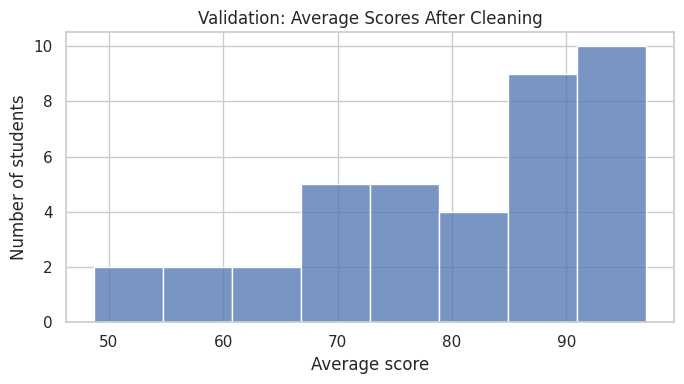

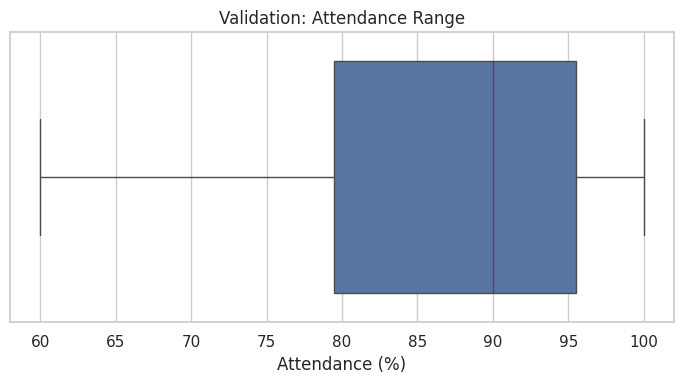

In [12]:
# -------------------------
# 7. OPTIONAL VALIDATION CHARTS
# These are checks of the transformed dataset, not a full EDA section.
# -------------------------
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 4))
sns.histplot(data=clean_df, x="average_score", bins=8)
plt.title("Validation: Average Scores After Cleaning")
plt.xlabel("Average score")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=clean_df, x="attendance_pct")
plt.title("Validation: Attendance Range")
plt.xlabel("Attendance (%)")
plt.tight_layout()
plt.show()


In [13]:
# -------------------------
# 8. LOAD
# -------------------------
output_file = "student_performance_cleaned.csv"
clean_df.to_csv(output_file, index=False)

print(f"\nETL complete. Cleaned data saved to: {output_file}")
print("Rows loaded:", len(clean_df))



ETL complete. Cleaned data saved to: student_performance_cleaned.csv
Rows loaded: 39
